# Chapter 6 · Inverse Kinematics and Trajectories

**Companion notebook to *Mathematics for Robotics: A Beginner's Guide*** · ROSFORGE · rosforge.com

Read Chapter 6 of the book, then run each cell here to see the idea at work. Change the numbers and re-run: that is the fastest way to build intuition. Section numbers below match the book.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 5)
deg = np.pi / 180
l1, l2 = 1.0, 1.0

def fk(q):
    return np.array([l1*np.cos(q[0]) + l2*np.cos(q[0]+q[1]), l1*np.sin(q[0]) + l2*np.sin(q[0]+q[1])])

def J(q):
    s1, c1, s12, c12 = np.sin(q[0]), np.cos(q[0]), np.sin(q[0]+q[1]), np.cos(q[0]+q[1])
    return np.array([[-l1*s1 - l2*s12, -l2*s12], [l1*c1 + l2*c12, l2*c12]])

def arm_pts(q):
    e = np.array([l1*np.cos(q[0]), l1*np.sin(q[0])]); return np.array([[0, 0], e, fk(q)])

def draw_arm(ax, q, color="C0", alpha=1.0):
    ax.plot(*arm_pts(q).T, "o-", lw=4, ms=9, color=color, alpha=alpha)

def setup(ax, lim=2.4, title=""):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(alpha=.3); ax.set_title(title)

## 6.1 Closed-form inverse kinematics
From the forward-kinematics equations, $x^2+y^2=l_1^2+l_2^2+2l_1l_2\cos q_2$, so $\cos q_2=\dfrac{x^2+y^2-l_1^2-l_2^2}{2l_1l_2}$ and $q_1=\operatorname{atan2}(y,x)-\operatorname{atan2}(l_2\sin q_2,\ l_1+l_2\cos q_2)$. There are normally **two** solutions (elbow up and down), and **none** if the target is out of reach.

elbow +1: q = [ 0. 90.] deg   hand = [1. 1.]
elbow -1: q = [ 90. -90.] deg   hand = [1. 1.]


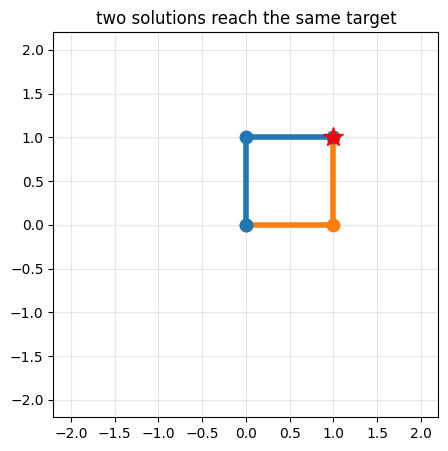

target (3, 0) is out of reach: None


In [2]:
def ik_2r(x, y, elbow=+1):
    c2 = (x**2 + y**2 - l1**2 - l2**2) / (2*l1*l2)
    if abs(c2) > 1: return None                                   # target outside the workspace
    q2 = elbow * np.arccos(c2)
    q1 = np.arctan2(y, x) - np.arctan2(l2*np.sin(q2), l1 + l2*np.cos(q2))
    return np.array([q1, q2])

target = np.array([1.0, 1.0]); fig, ax = plt.subplots()
for elbow, col in [(+1, "C1"), (-1, "C0")]:
    q = ik_2r(*target, elbow); print(f"elbow {elbow:+d}: q = {q/deg} deg   hand = {fk(q)}"); draw_arm(ax, q, col)
ax.plot(*target, "r*", ms=15); setup(ax, 2.2, "two solutions reach the same target"); plt.show()
print("target (3, 0) is out of reach:", ik_2r(3, 0))

## 6.2 Newton's method
Replace the curved problem by its linear approximation, solve that, and repeat. In one variable $x\leftarrow x+\dfrac{\text{target}-f(x)}{f'(x)}$; for an arm, solve $J\,\delta=e$ and set $q\leftarrow q+\delta$.

In [3]:
# warm-up: sqrt(2) by Newton
x = 1.0
for k in range(5):
    x = x + (2 - x**2) / (2 * x); print(f"step {k+1}: {x:.10f}")

step 1: 1.5000000000
step 2: 1.4166666667
step 3: 1.4142156863
step 4: 1.4142135624
step 5: 1.4142135624


step 0: q = [20. 60.]  deg   error = 4.36e-01
step 1: q = [-6.8141 91.0848]  deg   error = 1.10e-01
step 2: q = [-4.8525 83.1821]  deg   error = 5.42e-03
step 3: q = [-4.5399 82.8202]  deg   error = 1.49e-05
step 4: q = [-4.5397 82.8192]  deg   error = 1.14e-10
step 5: q = [-4.5397 82.8192]  deg   error = 2.48e-16
step 6: q = [-4.5397 82.8192]  deg   error = 1.11e-16


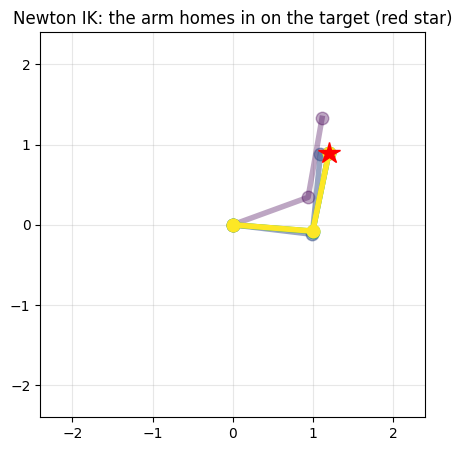

In [4]:
def newton_ik(target, q0, steps=10, verbose=True):
    q = np.array(q0, float); hist = [q.copy()]
    for k in range(steps):
        e = target - fk(q)
        if verbose: print(f"step {k}: q = {q/deg}  deg   error = {np.linalg.norm(e):.2e}")
        q = q + np.linalg.solve(J(q), e); hist.append(q.copy())
    return q, hist

target = np.array([1.2, 0.9])
q_sol, hist = newton_ik(target, [20*deg, 60*deg], steps=7)
fig, ax = plt.subplots()
for i, qq in enumerate(hist[:5]): draw_arm(ax, qq, color=plt.cm.viridis(i / 4), alpha=.35 + .65 * i / 4)
ax.plot(*target, "r*", ms=16); setup(ax, 2.4, "Newton IK: the arm homes in on the target (red star)"); plt.show()

## 6.3 Least squares and regularization
If $Ax=b$ has no exact solution, minimize $\|Ax-b\|^2$; the *normal equations* are $A^\top Ax=A^\top b$. If the problem is nearly singular, also penalize large solutions: minimize $\|Ax-b\|^2+\lambda^2\|x\|^2$, which gives $x=A^\top(AA^\top+\lambda^2I)^{-1}b$. For inverse kinematics this is the *damped step* $\delta=J^\top(JJ^\top+\lambda^2I)^{-1}e$.

minimum of g at t = 1.49
normal equations: [1.3391 0.8211]    library solver: [1.3391 0.8211]    agree: True
residual is perpendicular to the columns of A (A^T r = 0): True


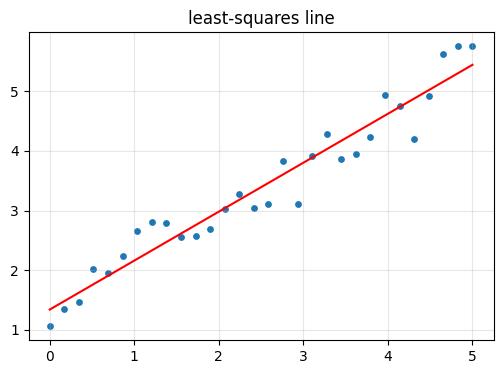

lambda = 0:  minimum at t = 2.500
lambda = 1:  minimum at t = 2.000
lambda = 2:  minimum at t = 1.250


In [5]:
# minimizing a quadratic: g(t) = (t-3)^2 + t^2  ->  slope 4t - 6 = 0  ->  t = 1.5
t = np.linspace(-1, 4, 200); g = lambda t: (t - 3)**2 + t**2
print("minimum of g at t =", t[np.argmin(g(t))].round(2))

# least squares: fit a line to noisy points (30 equations, 2 unknowns)
rng = np.random.default_rng(10); s = np.linspace(0, 5, 30); y = 1.5 + 0.8*s + rng.normal(scale=0.4, size=s.size)
A = np.column_stack([np.ones_like(s), s])
x_normal = np.linalg.solve(A.T @ A, A.T @ y); x_lstsq = np.linalg.lstsq(A, y, rcond=None)[0]
print("normal equations:", x_normal, "   library solver:", x_lstsq, "   agree:", np.allclose(x_normal, x_lstsq))
print("residual is perpendicular to the columns of A (A^T r = 0):", np.allclose(A.T @ (A @ x_normal - y), 0, atol=1e-9))
plt.figure(figsize=(6, 4)); plt.scatter(s, y, s=15); plt.plot(s, A @ x_normal, "r"); plt.grid(alpha=.3); plt.title("least-squares line"); plt.show()

# the effect of damping on  (2t-5)^2 + lambda^2 t^2 : minimum at t = 10 / (4 + lambda^2)
for lam in [0, 1, 2]: print(f"lambda = {lam}:  minimum at t = {10/(4 + lam**2):.3f}")

In [6]:
q_near = np.array([0.2, 1e-3])               # almost fully stretched: nearly singular
target = np.array([1.5, 0.5]); e = target - fk(q_near)

step_newton = np.linalg.solve(J(q_near), e)
lam = 0.1
step_dls = J(q_near).T @ np.linalg.solve(J(q_near) @ J(q_near).T + lam**2 * np.eye(2), e)
print("condition number of J here:", np.linalg.cond(J(q_near)))
print("plain Newton step (rad):", step_newton, "  size", np.linalg.norm(step_newton))
print("damped step      (rad):", step_dls, "  size", np.linalg.norm(step_dls))

condition number of J here: 4999.999633333628
plain Newton step (rad): [-430.3738  860.9388]   size 962.5161195611328
damped step      (rad): [0.0678 0.0554]   size 0.08751894411224849


## 6.4 Trajectories: moving smoothly
Require $h(0)=0$, $h(1)=1$ and zero velocity and acceleration at both ends: six conditions, so a polynomial of degree five, $h(s)=10s^3-15s^4+6s^5$. The joint motion is $q(t)=q_0+(q_1-q_0)\,h(t/T)$.

h(0), h(1) = 0 1   h'(0), h'(1) = 0 0   h''(0), h''(1) = 0 0


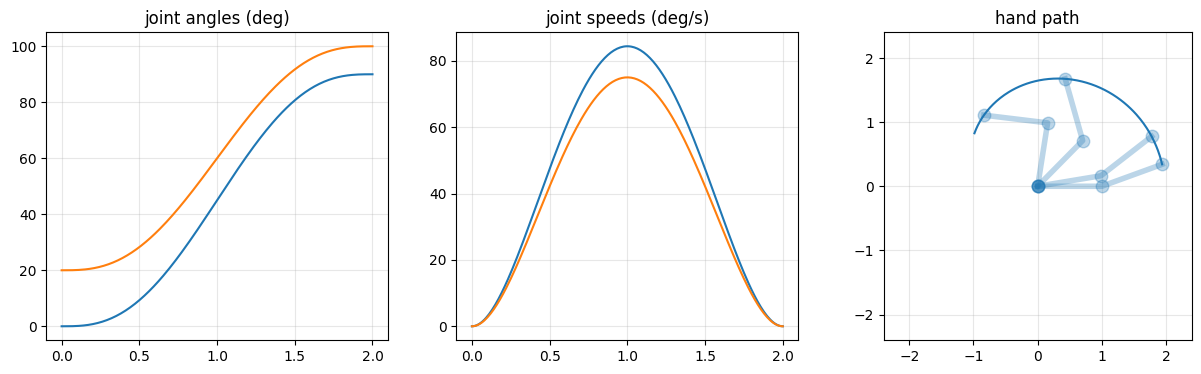

In [7]:
h  = lambda s: 10*s**3 - 15*s**4 + 6*s**5
hd = lambda s: 30*s**2 - 60*s**3 + 30*s**4
hdd = lambda s: 60*s - 180*s**2 + 120*s**3
print("h(0), h(1) =", h(0), h(1), "  h'(0), h'(1) =", hd(0), hd(1), "  h''(0), h''(1) =", hdd(0), hdd(1))

T = 2.0; qa, qb = np.array([0*deg, 20*deg]), np.array([90*deg, 100*deg]); ts = np.linspace(0, T, 200); s = ts / T
q_t = qa + np.outer(h(s), qb - qa)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ts, q_t / deg); axes[0].set_title("joint angles (deg)")
axes[1].plot(ts, np.outer(hd(s), qb - qa) / T / deg); axes[1].set_title("joint speeds (deg/s)")
path = np.array([fk(qq) for qq in q_t]); axes[2].plot(*path.T)
for qq in q_t[::50]: draw_arm(axes[2], qq, alpha=.3)
setup(axes[2], 2.4, "hand path"); [ax.grid(alpha=.3) for ax in axes[:2]]; plt.show()

In [8]:
# any wish-list of boundary conditions gives a linear system for the polynomial's coefficients
from math import factorial
def fit_poly(conds):
    n = len(conds) - 1
    row = lambda s, order: [0.0 if k < order else factorial(k)/factorial(k-order) * s**(k-order) for k in range(n + 1)]
    return np.linalg.solve(np.array([row(s, d) for s, d, _ in conds]), np.array([v for *_, v in conds], float))
print("cubic  :", fit_poly([(0, 0, 0), (1, 0, 1), (0, 1, 0), (1, 1, 0)]), "  -> 3 s^2 - 2 s^3")
print("quintic:", fit_poly([(0, 0, 0), (1, 0, 1), (0, 1, 0), (1, 1, 0), (0, 2, 0), (1, 2, 0)]), "  -> 10 s^3 - 15 s^4 + 6 s^5")

cubic  : [ 0.  0.  3. -2.]   -> 3 s^2 - 2 s^3
quintic: [  0.   0.   0.  10. -15.   6.]   -> 10 s^3 - 15 s^4 + 6 s^5


---
## Exercises

> **Exercise 6.1**
>
> Use Newton's method to estimate $\sqrt5$ from $x_0=2$ (two steps).

In [9]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 6.1** *(this is the book's Appendix B, checked in code)*

In [10]:
x0 = 2.0; x1 = x0 + (5 - x0**2) / (2*x0); x2 = x1 + (5 - x1**2) / (2*x1); print(x1, x2, np.sqrt(5)); assert np.isclose(x1, 2.25) and np.isclose(x2, 2.2361, atol=1e-4)

2.25 2.236111111111111 2.23606797749979


> **Exercise 6.2**
>
> For $l_1=l_2=1$ find $q_1,q_2$ so that the hand reaches $(0,2)$. Is the solution unique?

In [11]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 6.2** *(this is the book's Appendix B, checked in code)*

In [12]:
q = ik_2r(0, 2); print(q / deg); assert np.allclose(q / deg, [90, 0]) and np.allclose(fk(q), [0, 2])
print("unique: the target is on the edge of the workspace, where the two elbow solutions coincide")

[90.  0.]
unique: the target is on the edge of the workspace, where the two elbow solutions coincide


> **Exercise 6.3**
>
> Minimize $(2t-5)^2+t^2$ (so $\lambda=1$). Compare with the minimizer of $(2t-5)^2$.

In [13]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 6.3** *(this is the book's Appendix B, checked in code)*

In [14]:
print(10/(4 + 1), 10/(4 + 0)); assert 10/(4 + 1) == 2 and 10/4 == 2.5
print("derivative 4(2t-5) + 2t = 10t - 20 = 0 gives t = 2, closer to 0 than 2.5")

2.0 2.5
derivative 4(2t-5) + 2t = 10t - 20 = 0 gives t = 2, closer to 0 than 2.5


> **Exercise 6.4**
>
> Find the quadratic $h(s)=c_0+c_1s+c_2s^2$ with $h(0)=0$, $h(1)=1$, $h'(0)=0$.

In [15]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 6.4** *(this is the book's Appendix B, checked in code)*

In [16]:
c = fit_poly([(0, 0, 0), (1, 0, 1), (0, 1, 0)]); print(c); assert np.allclose(c, [0, 0, 1]); print("h(s) = s^2")

[0. 0. 1.]
h(s) = s^2


*Mathematics for Robotics: A Beginner's Guide* · ROSFORGE · rosforge.com